In [1]:
import re
import numpy as np
import pandas as pd

BASE = "/Users/parin/Desktop/prosecutor explorer/worcester"
wdisp_raw = pd.read_parquet(f"{BASE}/charges-disposed.parquet")
wfiled_raw = pd.read_parquet(f"{BASE}/charges-filed.parquet")
wbail_clean = pd.read_parquet(f"{BASE}/bail.parquet")
print(wdisp_raw.shape, wfiled_raw.shape, wbail_clean.shape)

(569235, 96) (594493, 95) (159561, 18)


In [2]:
%pip install "pyarrow<21"

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 30.8 MB 9.8 MB/s eta 0:00:011
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 21.0.0
    Uninstalling pyarrow-21.0.0:
      Successfully uninstalled pyarrow-21.0.0
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
YEARS = (2017, 2024)
MISSING_MAX = 0.20
MIN_CELL = 30
POP = {y: 862_111 for y in range(2017, 2025)}   # TODO: 2020 Census placeholder; swap in annual PEP estimates
EVENTS = {"MA CJ reform act": "2018-04-13", "COVID court closures": "2020-03-16"}
DEF_COL = "def_filled"

def pct(x): return (100 * x).round(1)
def share(s):
    t = s.value_counts(dropna=False)
    return pd.DataFrame({"n": t, "pct": pct(t / t.sum())})
def rate_by(frame, flag, by):
    t = frame.assign(f=np.asarray(flag)).groupby(by, observed=True).f.agg(n="size", k="sum")
    t["pct"] = pct(t.k / t.n)
    return t

In [4]:
W_DISPO = {
    "DISM": "dismissal", "DWOP": "dismissal", "DWP": "dismissal", "NOL": "dismissal",
    "PCNF": "dismissal", "AS": "dismissal",
    "PTP": "diversion", "DPCC": "diversion", "CATI": "diversion", "VAA": "diversion",
    "CWOF": "cwof", "GPCW": "cwof",
    # generic "Guilty" findings: plea OR bench/jury verdict, can't be separated
    "GPA": "plea", "GFL": "plea", "GFN": "plea", "SGL": "plea", "GYO": "plea",
    "DPA": "plea", "DFL": "plea", "DFN": "plea",
    "JTG": "trial_conviction", "JWG": "trial_conviction", "SJTL": "trial_conviction",
    "JWNG": "acquittal", "JTNG": "acquittal", "DIRV": "acquittal", "RFNG": "acquittal",
    "NGYO": "acquittal",
    "NCR": "other",   # not criminally responsible (mental illness), not an acquittal on the facts
    "NRSP": "civil", "RFN": "civil", "RFL": "civil", "RSP": "civil",
    "TR": "other", "RCH": "other", "FWOP": "other", "NCF": "other", "PCF": "other",
    "MT": "other", "DPCW": "other",
}
W_LESSER = {"SGL", "SJTL"}
RACE_MAP = {"White": "White", "Black": "Black", "Hispanic": "Hispanic", "Asian": "Asian",
            "American Indian": "Other", "Pacific Islander": "Other", "Middle Eastern": "Other",
            "Other": "Other", "Unknown": "Unknown"}

def prep(d):
    d = d.copy()
    n = len(d); d = d.drop_duplicates(); print(f"dropped {n - len(d):,} dup rows")
    for col in ("charge_description", "disposition_description", "sentence_description"):
        d[col] = (d[col].astype("string").str.replace("Â§", "§", regex=False)
                  .str.replace("Â—", "-", regex=False).str.replace("Â", "", regex=False).str.strip())
    for col in ("filing_date", "disposition_date"):
        d[col] = pd.to_datetime(d[col], errors="coerce")
    bad = (d.disposition_date < "1986-01-01") | (d.disposition_date > pd.Timestamp.today())
    d.loc[bad, "disposition_date"] = pd.NaT

    g = d.groupby("case_id").defendant_id
    n_ids = g.nunique()
    d["def_filled"] = d.defendant_id.fillna(d.case_id.map(g.first().where(n_ids.eq(1))))
    d["case_key"] = d.case_id.astype(str) + "|" + d.def_filled.astype(str)

    d["outcome"] = d.disposition_code.map(W_DISPO)
    d.loc[d.disposition_code.isna(), "outcome"] = "pending"
    print("unmapped codes:", d.loc[d.outcome.isna(), "disposition_code"].value_counts().to_dict())
    d["outcome"] = d.outcome.fillna("other")
    d["lesser"] = d.disposition_code.isin(W_LESSER)

    d["placeholder"] = d.charge_code.astype(str).isin(["666666", "999999"])
    d["offense_cat"] = np.where(d.placeholder, "Other/Unknown", d.offense_group.fillna("Other/Unknown"))
    d["is_civil"] = (d.charge_description.str.contains(r"\s\*(?:\s|$)", na=False)
                     | d.outcome.eq("civil"))
    superior = d.court_name.astype(str).str.contains("Superior", case=False, na=False)
    d["sev_rank"] = np.where(d.is_civil, 0, np.where(superior, 3, 1))   # no statutory class available
    d["sev_class"] = np.select([d.is_civil, superior], ["Civil", "Superior Ct"], "District Ct")

    d["race"] = d.defendant_race.map(RACE_MAP).fillna("Unknown")
    d["sex"] = d.defendant_sex.map({"Male": "Male", "Female": "Female"}).fillna("Unknown")
    d["pend"] = d.outcome.eq("pending")
    print("filing range:", d.filing_date.min(), "to", d.filing_date.max())
    return d

df = prep(wdisp_raw)
dff = prep(wfiled_raw)
print(df.race.value_counts().to_string())

dropped 0 dup rows
unmapped codes: {}
filing range: 2000-07-05 00:00:00 to 2026-03-19 00:00:00
dropped 0 dup rows
unmapped codes: {'DVA': 1}
filing range: 2014-01-02 00:00:00 to 2025-12-31 00:00:00
race
White       344921
Hispanic    102874
Black        72351
Unknown      41460
Asian         6511
Other         1118


In [5]:
OUTCOME_RANK = {"trial_conviction": 8, "plea": 7, "cwof": 6, "acquittal": 5, "diversion": 4,
                "dismissal": 3, "declined": 2, "other": 1, "pending": 0}

def build_cases(d):
    lead = (d.sort_values(["case_key", "sev_rank"], ascending=[True, False])
              .drop_duplicates("case_key").set_index("case_key")
              [[DEF_COL, "sev_rank", "sev_class", "offense_cat", "race", "sex", "charge_description", "court_name"]])
    agg = d.groupby("case_key").agg(filed=("filing_date", "min"), dispo=("disposition_date", "max"),
                                    n_charges=("case_key", "size"),
                                    all_civil=("is_civil", "all"), any_pending=("pend", "any"))
    cr = d[~d.is_civil]
    o = (cr.assign(r=cr.outcome.map(OUTCOME_RANK)).sort_values("r", ascending=False)
           .drop_duplicates("case_key").set_index("case_key").outcome)
    c = lead.join(agg).join(o)
    c["outcome"] = c.outcome.fillna("civil")
    c["any_lesser_plea"] = c.index.isin(cr.loc[cr.outcome.eq("plea") & cr.lesser, "case_key"].unique())
    c["year"] = c.filed.dt.year
    dd = (c.dispo - c.filed).dt.days
    c["days_to_dispo"] = dd.where((dd >= 0) & ~c.any_pending)
    return c

cases_all = build_cases(df)
p = cases_all[~cases_all.all_civil & cases_all[DEF_COL].notna()].sort_values("filed")
cases_all["prior_cases"] = p.groupby(DEF_COL).cumcount().reindex(cases_all.index)
cases_all["prior_level"] = (pd.cut(cases_all.prior_cases, [-1, 0, 2, np.inf], labels=["0", "1-2", "3+"])
                              .astype(object).fillna("Unknown"))

cases = cases_all[cases_all.year.between(*YEARS)]
cases_filed = build_cases(dff).pipe(lambda c: c[c.year.between(*YEARS)])   # volume, incl. open cases
ch_w = df[df.filing_date.dt.year.between(*YEARS)]

crim = cases[~cases.all_civil & cases.outcome.ne("pending")]
convicted = crim[crim.outcome.isin(["plea", "trial_conviction"])]
print(len(cases_filed), "filed cases |", len(crim), "criminal disposed |", len(convicted), "convicted")

# cross-check vs raw extract (23,685 / 22,656 / 17,895)
print(cases_filed[~cases_filed.all_civil].groupby("year").size().loc[2017:2019])

192154 filed cases | 159571 criminal disposed | 32916 convicted
year
2017    25715
2018    25192
2019    24735
dtype: int64


In [6]:
def sent_class(txt):
    if not isinstance(txt, str) or not txt.strip():
        return None
    t = txt.lower()
    if "susp" in t: return "Probation (suspended)"
    if re.search(r"mci|hoc|house of corr|jail|prison|committ|cmtd|dys|\bcom\b", t): return "Incarceration"
    if "prob" in t: return "Probation"
    if re.search(r"fine|cost|restitution|\brest\b|vwf|community serv|\$", t): return "Fine/other"
    if "filed" in t: return "Filed (no sentence)"
    return None

CT_LINE = re.compile(r"^\s*cts?\.?\s*([\d,\s&\-and]+);?(.*)$", re.I)
def split_counts(text):
    by_ct, default = {}, None
    for line in str(text).splitlines():
        m = CT_LINE.match(line)
        if not m:
            default = (default or "") + " " + line
            continue
        nums = set()
        for a, b in re.findall(r"(\d+)\s*-\s*(\d+)", m.group(1)):
            nums.update(range(int(a), int(b) + 1))
        nums.update(int(n) for n in re.findall(r"\d+", re.sub(r"\d+\s*-\s*\d+", "", m.group(1))))
        for n in nums:
            by_ct[n] = m.group(2)
    return by_ct, default

conv_all = df[df.outcome.isin(["plea", "trial_conviction"]) & ~df.is_civil].copy()
cache = {t: split_counts(t) for t in conv_all.sentence_description.dropna().unique()}
def seg(row):
    t = row.sentence_description
    if pd.isna(t): return None
    by_ct, default = cache[t]
    ct = pd.to_numeric(row.charge_count_number, errors="coerce")
    return by_ct.get(int(ct), default) if pd.notna(ct) else default
conv_all["sent_seg"] = conv_all.apply(seg, axis=1)

conv_all["sent"] = conv_all.sent_seg.map(sent_class)
conv_all.loc[conv_all.sent.isna() & conv_all.disposition_code.eq("GFL"), "sent"] = "Filed (no sentence)"
conv_all.loc[conv_all.sent.isna() & conv_all.disposition_code.eq("GFN"), "sent"] = "Fine/other"
conv_all["sent"] = conv_all.sent.fillna("Missing")

UNIT = {"y": 365.25, "m": 30.44, "d": 1, "w": 7}
TERM = re.compile(r"(\d+(?:\.\d+)?)\s*(?:-|to)?\s*(\d+(?:\.\d+)?)?\s*(yrs?|years?|mos?|months?|days?|wks?|weeks?)\b", re.I)
def term_days(s):
    if not isinstance(s, str) or "susp" in s.lower():
        return (np.nan, np.nan)
    m = TERM.search(s)
    if not m:
        return (np.nan, np.nan)
    u = UNIT[m.group(3)[0].lower()]
    lo = float(m.group(1)); hi = float(m.group(2)) if m.group(2) else lo
    return (lo * u, hi * u)
terms = conv_all.sent_seg.map(term_days)
conv_all["term_min_days"] = terms.str[0]
conv_all["term_max_days"] = terms.str[1]

cv_w = conv_all[conv_all.filing_date.dt.year.between(*YEARS)]
sent_missing = cv_w.sent.eq("Missing").mean()
HAS_INCARC = sent_missing <= MISSING_MAX
print(f"sentence missing among convictions: {100 * sent_missing:.1f}% -> HAS_INCARC={HAS_INCARC}")
print(cv_w.sent.value_counts().to_string())

rank = {"Incarceration": 6, "Probation (suspended)": 5, "Probation": 5, "Fine/other": 4,
        "Filed (no sentence)": 2, "Missing": 0}
case_sent = (conv_all.assign(r=conv_all.sent.map(rank)).sort_values("r", ascending=False)
                     .drop_duplicates("case_key").set_index("case_key").sent)

sentence missing among convictions: 11.3% -> HAS_INCARC=True
sent
Incarceration            16888
Probation                11003
Filed (no sentence)      10978
Missing                   5955
Fine/other                5211
Probation (suspended)     2723


In [7]:
# bail file profile
info = pd.DataFrame({
    "dtype": wbail_clean.dtypes.astype(str),
    "pct_null": (100 * wbail_clean.isna().mean()).round(1),
    "n_unique": wbail_clean.nunique(),
    "example": wbail_clean.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
print(info.to_string())
for c in wbail_clean.columns:
    if wbail_clean[c].dtype == object and wbail_clean[c].nunique() <= 40:
        print(f"\n{c}\n", wbail_clean[c].value_counts(dropna=False).head(20).to_string())

                                  dtype  pct_null  n_unique                                                                                                                                                                                      example
county                           object       0.0         1                                                                                                                                                                                    worcester
source_prr                       object       0.0         1                                                                                                                                                                           WORCESTER-PRR-2026
case_id                          object       0.0    130087                                                                                                                                                                               03-01-010861-1
bail

In [8]:
# data coverage
yr = ch_w.filing_date.dt.year
inc_w = cv_w[cv_w.sent.eq("Incarceration")]
groups = [
    ({"defendant_id": ch_w[DEF_COL].isna(), "filing_date": ch_w.filing_date.isna(),
      "disposition_date": ch_w.disposition_date.isna(),
      "charge_code": ch_w.charge_code.isna() | ch_w.placeholder,
      "disposition_code": ch_w.disposition_code.isna(),
      "race": ch_w.race.eq("Unknown"), "sex": ch_w.sex.eq("Unknown"),
      "court": ch_w.court_name.isna(), "offense_group": ch_w.offense_cat.eq("Other/Unknown")}, yr),
    ({"sentence_type (convictions)": cv_w.sent.eq("Missing")}, cv_w.filing_date.dt.year),
    ({"sentence_length (incarcerated)": inc_w.term_max_days.isna()}, inc_w.filing_date.dt.year),
]
rows = []
for checks, yrs in groups:
    for k, miss in checks.items():
        by_year = (~miss).groupby(yrs).mean()
        rows.append(dict(field=k, pct_missing=pct(miss.mean()),
                         years_available=",".join(str(int(y)) for y, v in by_year.items() if v > 0),
                         status="ok" if miss.mean() <= MISSING_MAX else "insufficient data"))
rows += [dict(field="severity (felony/misd)", pct_missing=100.0, years_available="",
              status="insufficient data (charge_category 0% populated)"),
         dict(field="dob/age", pct_missing=100.0, years_available="", status="insufficient data (not delivered)"),
         dict(field="plea vs trial verdict", pct_missing=None, years_available="",
              status="not separable (generic 'Guilty' code)")]
coverage = pd.DataFrame(rows)
coverage

,field,pct_missing,years_available,status
0,defendant_id,0.0,"2017,2018,2019,2020,2021,2022,2023,2024",ok
1,filing_date,0.0,"2017,2018,2019,2020,2021,2022,2023,2024",ok
2,disposition_date,0.0,"2017,2018,2019,2020,2021,2022,2023,2024",ok
3,charge_code,0.4,"2017,2018,2019,2020,2021,2022,2023,2024",ok
4,disposition_code,0.0,"2017,2018,2019,2020,2021,2022,2023,2024",ok
5,race,6.8,"2017,2018,2019,2020,2021,2022,2023,2024",ok
6,sex,0.8,"2017,2018,2019,2020,2021,2022,2023,2024",ok
7,court,0.0,"2017,2018,2019,2020,2021,2022,2023,2024",ok
8,offense_group,1.5,"2017,2018,2019,2020,2021,2022,2023,2024",ok
9,sentence_type (convictions),11.3,"2017,2018,2019,2020,2021,2022,2023,2024",ok


In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm

EXCLUDE = {"Motor Vehicle"}          # minor traffic; add "OUI/DUI" if the client wants all MV offenses out
DROP_UNK_WITH_TRAFFIC = False        # set True if the Other/Unknown check below shows traffic-adjacent charges
OUTCOMES = ["dismissal", "diversion", "cwof", "conviction", "not_guilty_at_trial", "other"]
SENTS = ["Incarceration", "Probation", "Fine/other", "Filed (no sentence)", "Missing"]
RACES = ["White", "Black", "Hispanic", "Asian", "Other", "Unknown"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3})

def events(ax):
    for lbl, d in EVENTS.items():
        t = pd.Timestamp(d); x = t.year + (t.dayofyear - 1) / 365
        ax.axvline(x, color="grey", ls="--", lw=1)
        ax.text(x, ax.get_ylim()[1], f" {lbl}", fontsize=8, va="top", color="grey")

def case_traits(d):
    """traffic-only flag + lead offense (known offenses beat traffic and Other/Unknown)"""
    x = d.assign(ex=d.offense_cat.isin(EXCLUDE),
                 unk=d.offense_cat.eq("Other/Unknown"),
                 cc=pd.to_numeric(d.charge_count_number, errors="coerce"))
    g = x.assign(ex_or_unk=x.ex | x.unk).groupby("case_key").agg(
        all_ex=("ex", "all"), any_ex=("ex", "any"), all_ex_or_unk=("ex_or_unk", "all"))
    traffic_only = g.all_ex | (DROP_UNK_WITH_TRAFFIC & g.any_ex & g.all_ex_or_unk)
    lead = (x.sort_values(["case_key", "ex", "unk", "sev_rank", "cc"],
                          ascending=[True, True, True, False, True])
              .drop_duplicates("case_key").set_index("case_key").offense_cat)
    return traffic_only, lead

def clean(c, d):
    t, lead = case_traits(d)
    c = c.assign(traffic_only=t.reindex(c.index).fillna(False).astype(bool),
                 offense_cat=lead.reindex(c.index))
    return c[~c.all_civil & ~c.traffic_only]

vol_c = clean(cases_filed, dff)          # Q1-2: every filed case, open ones included
cs = clean(cases, df)                    # Q3-8: disposed extract
done = cs[~cs.any_pending]               # every charge has a final disposition
conv = done[done.outcome.isin(["plea", "trial_conviction"])].copy()
conv["sent"] = (case_sent.reindex(conv.index)
                .replace({"Probation (suspended)": "Probation"}).fillna("Missing"))
known = conv[conv.sent.ne("Missing")]
print(f"{len(vol_c):,} filed | {len(done):,} disposed | {len(conv):,} convicted")

118,262 filed | 103,561 disposed | 29,252 convicted


In [10]:
# Other/Unknown check: what are these charges? decides DROP_UNK_WITH_TRAFFIC above
unk = vol_c.index[vol_c.offense_cat.eq("Other/Unknown")]
x = dff[dff.case_key.isin(unk) & ~dff.offense_cat.isin(EXCLUDE)]
print(f"Other/Unknown cases: {len(unk):,} ({100 * len(unk) / len(vol_c):.1f}%)")
print(f"placeholder codes: {100 * x.placeholder.mean():.1f}%")
print(f"also have a traffic charge: "
      f"{100 * dff[dff.case_key.isin(unk)].groupby('case_key').offense_cat.apply(lambda s: s.isin(EXCLUDE).any()).mean():.1f}%")
display(x.charge_description.value_counts().head(30))

Other/Unknown cases: 16,144 (13.7%)
placeholder codes: 2.1%
also have a traffic charge: 4.3%


charge_description
DNA DATABASE SAMPLE, FAIL TO PROVIDE c22E §11               372
MISCELLANEOUS MUNIC ORDINANCE/BYLAW VIOL                    324
DOG, FAIL LICENSE c140 §137                                 269
REGISTRATION STICKER MISSING * 540 CMR §2.05(6)(a)          113
LEASED PERSONALTY, FAIL RETURN c266 §87                      97
MASS PIKE - TOO CLOSE                                        73
HEADLIGHTS, FAIL DIM * 540 CMR §22.05(2)                     67
ACCESSORY AFTER THE FACT c274 §4                             60
DOG/CAT RABIES VACCINATION VIOLATION c140 §145B              55
LOAD UNSECURED/UNCOVERED * c85 §36                           46
AFTERMARKET LIGHTING, NONCOMPLIANT * 540 CMR §22.07          44
RAILROAD TRACK, WALK/RIDE ON c160 §218                       44
SNOW/REC VEH-PUBLIC WAY VIOL  c90B §25                       41
TRASH, LITTER c270 §16                                       41
MOTOR CARRIER SAFETY VIOLATION 540 CMR §14.03                30
ENTICE CHILD UNDER 16

## Q1 + Q2 > Volume & Per Capita

,cases,yoy_pct,vs_2017_pct,per_10k,disposed_share
year,,,,,
2017,18069,NaN,0.0,209.6,91.2
2018,17440,-3.5,-3.5,202.3,91.2
2019,16639,-4.6,-7.9,193.0,89.4
2020,12153,-27.0,-32.7,141.0,88.7
2021,12877,6.0,-28.7,149.4,86.2
2022,12754,-1.0,-29.4,147.9,85.8
2023,13594,6.6,-24.8,157.7,86.0
2024,14736,8.4,-18.4,170.9,80.0


,n,pct
offense_cat,,
Domestic Violence,18942,16.0
Other/Unknown,16144,13.7
OUI/DUI,13651,11.5
Assault & Battery,11860,10.0
Larceny/Theft,11558,9.8


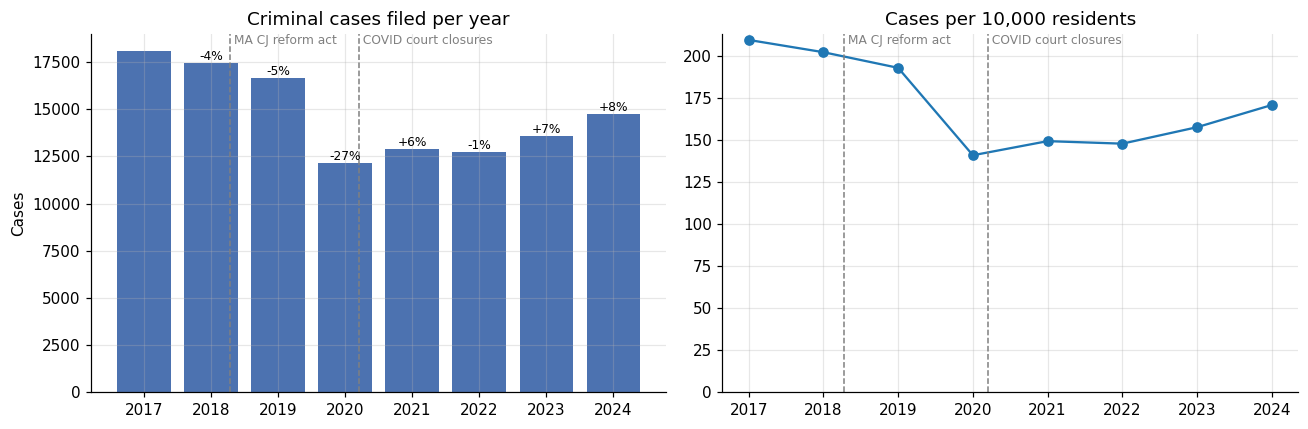

In [11]:
vol = vol_c.groupby("year").size().rename("cases").to_frame()
vol["yoy_pct"] = pct(vol.cases.pct_change())
vol["vs_2017_pct"] = pct(vol.cases / vol.cases.iloc[0] - 1)
vol["per_10k"] = (vol.cases / vol.index.map(POP) * 1e4).round(1)
vol["disposed_share"] = pct(done.groupby("year").size() / vol.cases)   # shows how open recent years are
display(vol, share(vol_c.offense_cat).head(5))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(vol.index, vol.cases, color="#4C72B0")
for x_, y_, p_ in zip(vol.index, vol.cases, vol.yoy_pct):
    if pd.notna(p_): a1.text(x_, y_, f"{p_:+.0f}%", ha="center", va="bottom", fontsize=8)
a1.set(title="Criminal cases filed per year", ylabel="Cases")
a2.plot(vol.index, vol.per_10k, marker="o")
a2.set(title="Cases per 10,000 residents", ylim=(0, None))
for a in (a1, a2): events(a)
plt.tight_layout(); plt.show()

Traffic-only cases (Motor Vehicle) are excluded. Per-capita uses a flat 2020 Census population until annual estimates are added.

## Q3 > Case Outcomes

,n,pct
outcome,,
dismissal,45146,43.6
diversion,4477,4.3
cwof,20455,19.8
conviction,29252,28.2
not_guilty_at_trial,3976,3.8
other,255,0.2


outcome,dismissal,diversion,cwof,conviction,not_guilty_at_trial,other
year,,,,,,
2017,40.8,4.4,18.9,31.5,4.2,0.2
2018,40.0,4.3,19.7,31.5,4.2,0.3
2019,41.2,4.4,19.7,30.0,4.5,0.3
2020,47.0,3.7,18.2,27.4,3.4,0.3
2021,44.5,4.4,20.0,27.6,3.3,0.2
2022,44.5,4.7,20.3,27.1,3.1,0.3
2023,46.3,4.1,21.4,24.4,3.6,0.2
2024,47.8,4.5,20.2,23.4,3.9,0.2


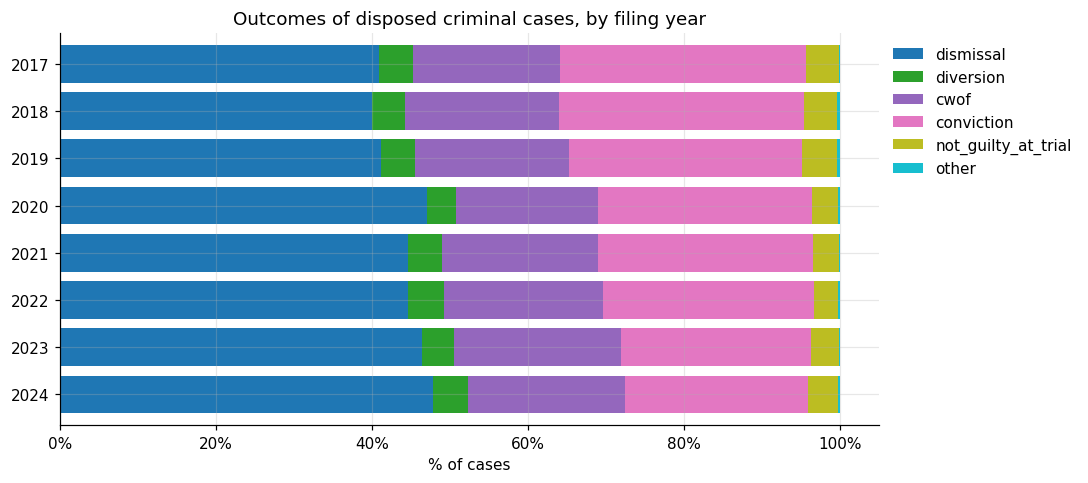

In [12]:
rep = done.outcome.replace({"plea": "conviction", "trial_conviction": "conviction",
                            "acquittal": "not_guilty_at_trial"})
oc = pd.crosstab(done.year, rep, normalize="index").reindex(columns=OUTCOMES, fill_value=0) * 100
display(share(rep).reindex(OUTCOMES), oc.round(1))

ax = oc.plot.barh(stacked=True, figsize=(10, 4.5), width=.8, colormap="tab10")
ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title="Outcomes of disposed criminal cases, by filing year", xlabel="% of cases", ylabel="")
ax.legend(bbox_to_anchor=(1, 1), frameon=False); plt.tight_layout(); plt.show()

Worcester records most guilty findings with a generic "Guilty" code that doesn't separate pleas from trial verdicts, so plea and trial conviction rates aren't reported. Only 80% of 2024 cases are disposed so far, and the open ones skew toward long cases, so part of the 2023-24 rise in dismissals reflects censoring.

## Q4 > Sentencing

,n,pct
sent,,
Incarceration,10619,36.3
Probation,8600,29.4
Fine/other,3282,11.2
Filed (no sentence),4597,15.7
Missing,2154,7.4


sent,Incarceration,Probation,Fine/other,Filed (no sentence),Missing
year,,,,,
2017,36.5,27.7,14.2,14.2,7.5
2018,35.2,28.9,13.0,15.1,7.9
2019,34.1,29.6,13.2,16.1,7.0
2020,35.8,30.1,10.6,16.8,6.8
2021,37.1,30.7,8.9,16.3,6.9
2022,39.9,31.1,7.7,15.1,6.3
2023,37.7,29.0,9.0,15.9,8.3
2024,35.8,29.7,8.6,17.9,8.0


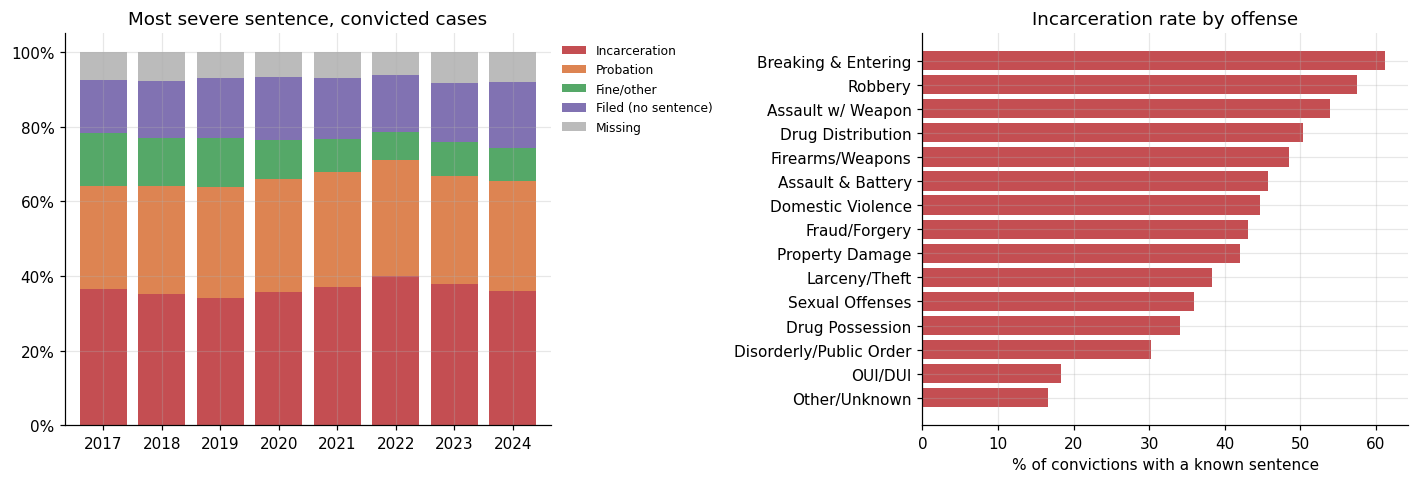

In [13]:
sc = pd.crosstab(conv.year, conv.sent, normalize="index").reindex(columns=SENTS, fill_value=0) * 100
display(share(conv.sent).reindex(SENTS), sc.round(1))
inc_off = (rate_by(known, known.sent.eq("Incarceration"), "offense_cat")
           .query("n >= @MIN_CELL").sort_values("pct"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
sc.plot.bar(stacked=True, ax=a1, width=.8, rot=0,
            color=["#C44E52", "#DD8452", "#55A868", "#8172B2", "#BBBBBB"])
a1.yaxis.set_major_formatter(mtick.PercentFormatter())
a1.set(title="Most severe sentence, convicted cases", xlabel="")
a1.legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
a2.barh(inc_off.index, inc_off.pct, color="#C44E52")
a2.set(title="Incarceration rate by offense", xlabel="% of convictions with a known sentence")
plt.tight_layout(); plt.show()

Sentence type is parsed from free text. Suspended sentences count as probation.

## Q5 > Pretrial Detention and Bail

bail record coverage: 86.0%


,value
cases with bail decision,82415.0
% released PR,60.8
% cash bail set,35.0
% held without bail,4.2
% detained at arraignment,29.7
% of cash-bail cases unable to post,72.6
median bail ($),500.0


,released_PR,cash_bail,held_no_bail,unable_to_post
year,,,,
2017,59.5,36.7,3.8,83.2
2018,59.4,36.2,4.4,81.3
2019,60.2,36.3,3.4,76.3
2020,59.5,36.5,4.0,69.6
2021,60.5,34.8,4.6,67.8
2022,60.5,34.6,4.8,67.5
2023,62.1,33.3,4.6,62.8
2024,65.2,30.5,4.3,63.4


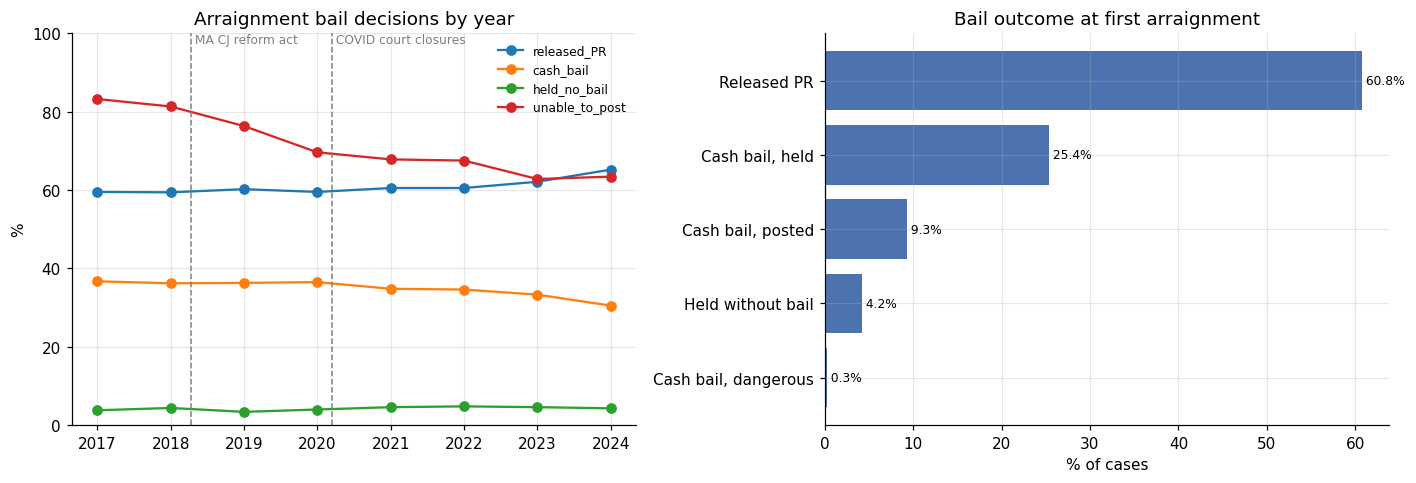

In [14]:
BAIL_MAP = {
    "PRN": ("Released PR", False, False),          # (category, cash_bail_set, detained)
    "PRC": ("Released PR", False, False),
    "DPR": ("Released PR", False, False),          # found dangerous, still released PR
    "RTN": ("Released PR", False, False),
    "RCB": ("Cash bail, posted", True, False),
    "SUR": ("Cash bail, posted", True, False),     # surety
    "ICBS": ("Cash bail, held", True, True),       # bail set, couldn't post
    "FDB": ("Cash bail, dangerous", True, None),   # custody status unclear
    "HWOB": ("Held without bail", False, True),
    "DHNB": ("Held without bail", False, True),    # dangerousness (58A)
    "ICNB": ("Held without bail", False, True),
    "NS": ("No status", None, None),
    "BAIL": ("No status", None, None),
}
b = wbail_clean.copy()
b["case_id"] = b.case_id.astype(str).str.strip()
b = b[b.bail_date.dt.year.between(YEARS[0], YEARS[1] + 1)]      # drops junk dates (1941, 2035)
b[["bail_cat", "cash_set", "detained"]] = pd.DataFrame(b.bail_status_code.map(BAIL_MAP).tolist(), index=b.index)
arr = b[b.hearing_type.eq("ARR")].sort_values("bail_date").drop_duplicates("case_id").set_index("case_id")

cb = cs.assign(case_id=cs.index.str.split("|").str[0])
cb = cb.join(arr[["bail_cat", "cash_set", "detained", "bail_amount_set"]], on="case_id")
print(f"bail record coverage: {100 * cb.bail_cat.notna().mean():.1f}%")
bb = cb[cb.bail_cat.notna() & cb.bail_cat.ne("No status")].copy()
bb["cash"] = bb.cash_set.astype(bool)
cash = bb[bb.cash]

q5 = pd.Series({
    "cases with bail decision": len(bb),
    "% released PR": pct(bb.bail_cat.eq("Released PR").mean()),
    "% cash bail set": pct(bb.cash.mean()),
    "% held without bail": pct(bb.bail_cat.eq("Held without bail").mean()),
    "% detained at arraignment": pct(bb.loc[bb.detained.notna(), "detained"].astype(bool).mean()),
    "% of cash-bail cases unable to post": pct(cash.bail_cat.eq("Cash bail, held").mean()),
    "median bail ($)": cash.loc[cash.bail_amount_set > 0, "bail_amount_set"].median(),
}).to_frame("value")
by_yr = bb.groupby("year").agg(
    released_PR=("bail_cat", lambda s: 100 * s.eq("Released PR").mean()),
    cash_bail=("cash", lambda s: 100 * s.mean()),
    held_no_bail=("bail_cat", lambda s: 100 * s.eq("Held without bail").mean()))
by_yr = by_yr.join(cash.groupby("year").bail_cat
                   .apply(lambda s: 100 * s.eq("Cash bail, held").mean()).rename("unable_to_post")).round(1)
display(q5, by_yr)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
by_yr.plot(marker="o", ax=a1)
a1.set(title="Arraignment bail decisions by year", ylabel="%", xlabel="", ylim=(0, 100))
a1.legend(frameon=False, fontsize=8); events(a1)
cats = share(bb.bail_cat)
a2.barh(cats.index.astype(str), cats.pct, color="#4C72B0"); a2.invert_yaxis()
for i, v in enumerate(cats.pct): a2.text(v, i, f" {v}%", va="center", fontsize=8)
a2.set(title="Bail outcome at first arraignment", xlabel="% of cases")
plt.tight_layout(); plt.show()

Cases with no bail record or "No status" are excluded from rates.

## Q6 > Time to Disposition

,n,median,q25,q75
sev_class,,,,
District Ct,100030,167.0,85.0,302.00
Superior Ct,1796,652.0,358.0,1077.25


,n,median,q25,q75
offense_cat,,,,
Other/Unknown,2006,82.0,35.00,191.00
Disorderly/Public Order,10568,120.0,51.00,255.00
Domestic Violence,18678,148.0,82.00,252.00
Larceny/Theft,11084,152.0,67.00,298.00
Property Damage,7049,164.0,94.00,289.00
Drug Possession,6408,177.0,90.00,328.00
Assault & Battery,11711,179.0,101.00,309.00
Breaking & Entering,2496,185.0,98.75,335.00
OUI/DUI,13365,192.0,92.00,336.00


,n,median,q25,q75
year,,,,
2017,16165,133.0,66.0,237.0
2018,15652,140.0,72.0,251.0
2019,14634,151.0,73.0,367.0
2020,10659,309.0,167.0,529.0
2021,10865,225.0,118.0,380.0
2022,10737,184.0,97.0,321.0
2023,11544,169.0,92.0,281.0
2024,11570,154.0,86.0,243.0


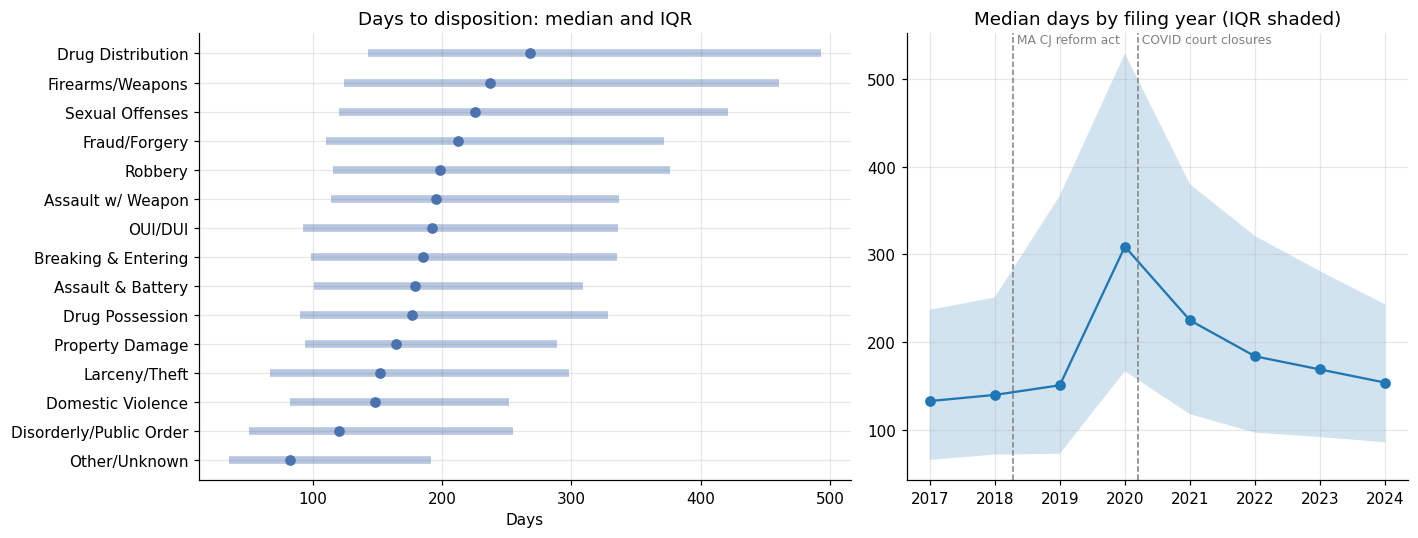

In [15]:
t = done[done.days_to_dispo.notna()]
def iqr_tab(g):
    return (t.groupby(g, observed=True).days_to_dispo
             .agg(n="size", median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
             .query("n >= @MIN_CELL"))
by_off, by_ct, by_y = iqr_tab("offense_cat").sort_values("median"), iqr_tab("sev_class"), iqr_tab("year")
display(by_ct, by_off, by_y)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})
y = list(range(len(by_off)))
a1.hlines(y, by_off.q25, by_off.q75, color="#4C72B0", alpha=.4, lw=5)
a1.plot(by_off["median"], y, "o", color="#4C72B0")
a1.set_yticks(y, by_off.index); a1.set(title="Days to disposition: median and IQR", xlabel="Days")
a2.plot(by_y.index, by_y["median"], marker="o"); a2.fill_between(by_y.index, by_y.q25, by_y.q75, alpha=.2)
a2.set(title="Median days by filing year (IQR shaded)", xlabel=""); events(a2)
plt.tight_layout(); plt.show()

Pending cases are excluded, so 2023-24 medians are biased low: the longest cases from those years are still open.

## Q7 > Disparities by Race and Sex

,n_disposed,dismissal_pct,n_convicted,incarc_pct,dismissal_RR,incarc_RR
race,,,,,,
White,66450,40.5,17280,36.0,1.00,1.00
Black,12921,50.2,3531,45.7,1.24,1.27
Hispanic,15978,46.9,5072,46.3,1.16,1.29
Asian,1123,45.8,224,36.2,1.13,1.01
Other,205,54.1,38,36.8,1.34,1.02
Unknown,6884,52.4,953,35.9,1.29,1.00


,n_disposed,dismissal_pct,n_convicted,incarc_pct,dismissal_RR,incarc_RR
sex,,,,,,
Male,77144,42.5,22363,41.2,1.0,1.00
Female,25687,46.8,4623,29.6,1.1,0.72


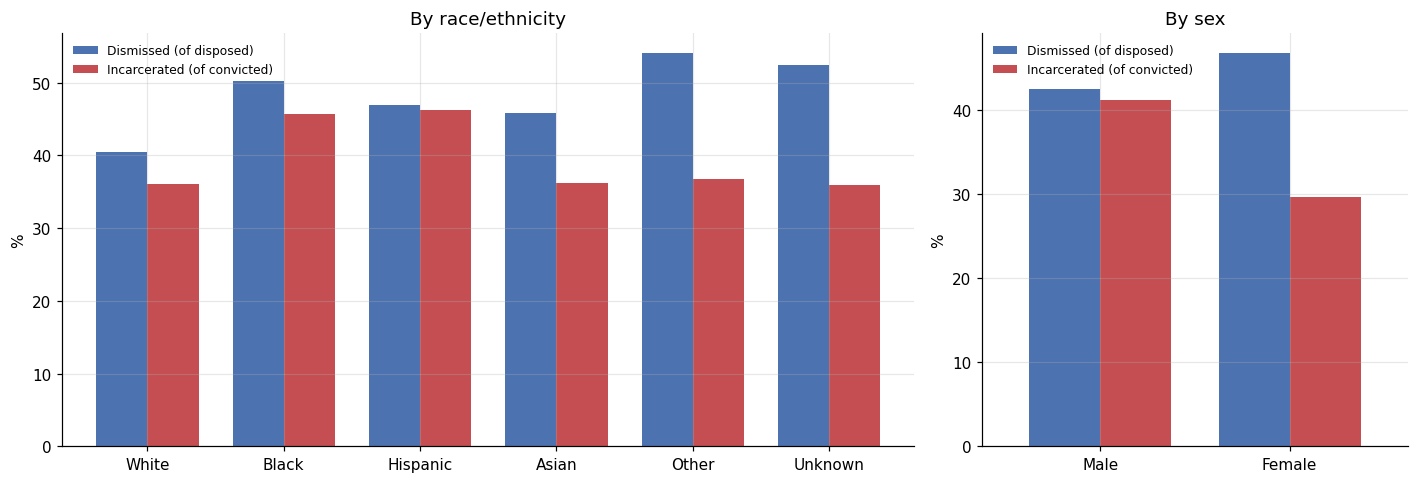

In [16]:
def disparity(col, ref):
    d = rate_by(done, done.outcome.eq("dismissal"), col).rename(columns={"n": "n_disposed", "pct": "dismissal_pct"})
    i = rate_by(known, known.sent.eq("Incarceration"), col).rename(columns={"n": "n_convicted", "pct": "incarc_pct"})
    t = d.drop(columns="k").join(i.drop(columns="k"))
    t.loc[t.n_disposed < MIN_CELL, "dismissal_pct"] = np.nan
    t.loc[t.n_convicted < MIN_CELL, "incarc_pct"] = np.nan
    t["dismissal_RR"] = (t.dismissal_pct / t.loc[ref, "dismissal_pct"]).round(2)
    t["incarc_RR"] = (t.incarc_pct / t.loc[ref, "incarc_pct"]).round(2)
    return t

race_t = disparity("race", "White").reindex(RACES)
sex_t = disparity("sex", "Male").reindex(["Male", "Female"])
display(race_t, sex_t)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
for ax, tb, ttl in zip(axes, [race_t, sex_t], ["By race/ethnicity", "By sex"]):
    tb[["dismissal_pct", "incarc_pct"]].dropna(how="all").plot.bar(ax=ax, width=.75, rot=0,
                                                                  color=["#4C72B0", "#C44E52"])
    ax.set(title=ttl, ylabel="%", xlabel="")
    ax.legend(["Dismissed (of disposed)", "Incarcerated (of convicted)"], frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## Q8 > Disparities with Controls

In [17]:
# run once if needed, then restart the kernel
# %pip install statsmodels

model                    Raw  Adjusted
outcome       race                    
Dismissal     Asian     1.24      1.25
              Black     1.48      1.35
              Hispanic  1.29      1.27
Incarceration Asian     1.01      1.06
              Black     1.49      1.36
              Hispanic  1.53      1.32

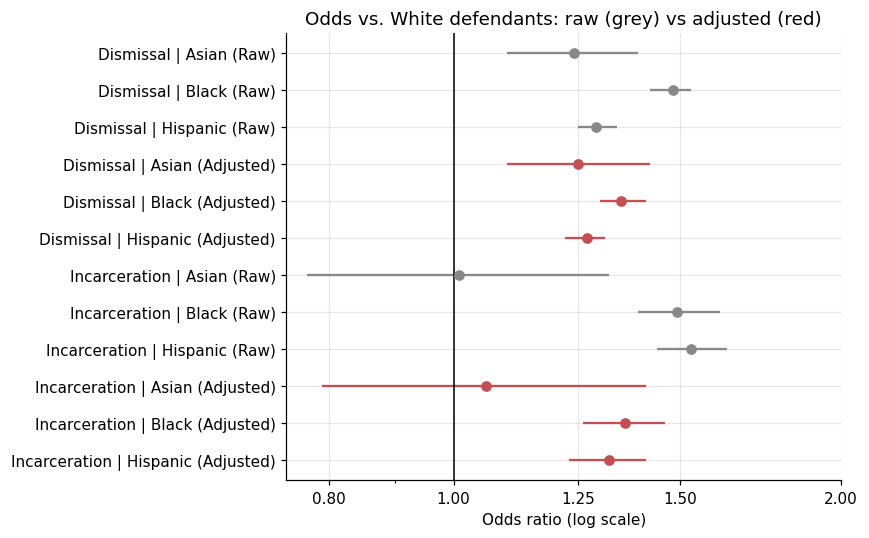

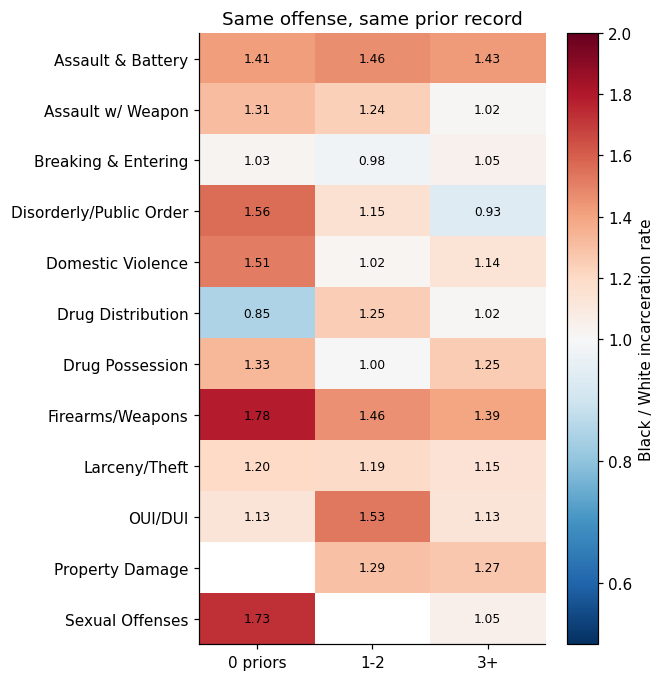

In [18]:
import statsmodels.formula.api as smf

RG = ["White", "Black", "Hispanic", "Asian"]
CTRL = ["offense_cat", "prior_level", "sev_class", "year"]

def race_or(data, controls):
    f = "y ~ C(race, Treatment('White'))" + "".join(f" + C({c})" for c in controls)
    r = smf.logit(f, data=data).fit(disp=0)
    ci = np.exp(r.conf_int())
    out = pd.DataFrame({"OR": np.exp(r.params), "lo": ci[0], "hi": ci[1]})
    out = out[out.index.str.startswith("C(race")]
    out.index = out.index.str.extract(r"T\.(\w+)\]")[0].values
    return out.round(2)

dm = done[done.race.isin(RG)].assign(y=lambda x: x.outcome.eq("dismissal").astype(int))
im = known[known.race.isin(RG)].assign(y=lambda x: x.sent.eq("Incarceration").astype(int))
res = []
for name, d in [("Dismissal", dm), ("Incarceration", im)]:
    d = d[d.groupby("offense_cat").y.transform("size") >= MIN_CELL]
    for label, ctrl in [("Raw", []), ("Adjusted", CTRL)]:
        res.append(race_or(d, ctrl).assign(outcome=name, model=label))
ors = pd.concat(res).rename_axis("race").reset_index()
display(ors.pivot_table(index=["outcome", "race"], columns="model", values="OR")[["Raw", "Adjusted"]])

# forest plot
p = ors.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 5))
for i, r in p.iterrows():
    ax.errorbar(r.OR, i, xerr=[[r.OR - r.lo], [r.hi - r.OR]], fmt="o",
                color="#888888" if r.model == "Raw" else "#C44E52")
ax.set_yticks(range(len(p)), p.outcome + " | " + p.race + " (" + p.model + ")")
ax.axvline(1, color="k", lw=1); ax.set_xscale("log"); ax.invert_yaxis()
ax.set_xticks([0.8, 1, 1.25, 1.5, 2])
ax.xaxis.set_major_formatter(mtick.ScalarFormatter()); ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.set(title="Odds vs. White defendants: raw (grey) vs adjusted (red)", xlabel="Odds ratio (log scale)")
plt.tight_layout(); plt.show()

# within-cell heatmap: Black/White incarceration rate ratio
g = im.groupby(["offense_cat", "prior_level", "race"]).y.agg(n="size", rate="mean").unstack("race")
ok = (g["n"]["White"] >= MIN_CELL) & (g["n"]["Black"] >= MIN_CELL)
rr = ((g["rate"]["Black"] / g["rate"]["White"]).where(ok)
      .unstack("prior_level").reindex(columns=["0", "1-2", "3+"]).dropna(how="all"))
fig, ax = plt.subplots(figsize=(6, .4 * len(rr) + 1.5))
im_ = ax.imshow(rr.values, cmap="RdBu_r", norm=TwoSlopeNorm(1, 0.5, 2), aspect="auto")
ax.set_xticks(range(3), ["0 priors", "1-2", "3+"]); ax.set_yticks(range(len(rr)), rr.index); ax.grid(False)
for (i, j), v in np.ndenumerate(rr.values):
    if pd.notna(v): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im_, label="Black / White incarceration rate"); ax.set_title("Same offense, same prior record")
plt.tight_layout(); plt.show()

Values are odds ratios: at a 36% base incarceration rate, an OR of 1.35 is roughly a 20% higher rate. Controls are offense category, prior record, court level and filing year; they don't include charge count or defense counsel type. Pretrial detention is deliberately left out because it likely sits on the path between race and sentencing. Blank heatmap cells had fewer than 30 cases in one group.